# DSC 106 Final Project — CMIP6 Climate Analysis

## Climate Change: Global Temperature Trends and Future Predictions

Research Question:
How do temperature trends differ across regions, and which regions are projected to warm the fastest?

Regions:
- North America
- South America
- Europe
- Africa
- Asia

## Cell 1 — setup

In [2]:
import numpy as np, pandas as pd, xarray as xr, gcsfs
from concurrent.futures import ThreadPoolExecutor
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
gcs = gcsfs.GCSFileSystem(token="anon")
print("xarray", xr.__version__)

xarray 2026.9.0


## Cell 2 — find (model, member, grid) triples with historical + SSP1-2.6 + SSP5-8.5 monthly `tas`

In [3]:
cat = pd.read_csv("https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv")
EXPS = ["historical", "ssp126", "ssp585"]
KEYS = ["source_id", "member_id", "grid_label"]

tas = cat[(cat.table_id == "Amon") & (cat.variable_id == "tas") & cat.experiment_id.isin(EXPS)]
tas = (tas.sort_values("version")
          .drop_duplicates(KEYS + ["experiment_id"], keep="last"))   # newest version only

cover = tas.groupby(KEYS).experiment_id.nunique()
full = cover[cover == 3].reset_index()[KEYS]

full["rank"] = list(zip(full.member_id != "r1i1p1f1", full.grid_label != "gn", full.member_id))
short = full.sort_values("rank").drop_duplicates("source_id").drop(columns="rank")

lf_cat = cat[(cat.table_id == "fx") & (cat.variable_id == "sftlf")]
lf = lf_cat[["source_id", "grid_label"]].drop_duplicates().assign(has_sftlf=True)
short = short.merge(lf, on=["source_id", "grid_label"], how="left")
short["has_sftlf"] = short.has_sftlf.eq(True)

cands = tas.merge(short[KEYS], on=KEYS)   # catalog rows (3 per model) for Cell 3

print("catalog rows:", len(cat))
print("tas Amon rows per experiment:\n", tas.experiment_id.value_counts().to_string())
print("matched (model, member, grid) triples:", len(full), "| distinct models:", short.source_id.nunique())
print(short.sort_values("source_id").to_string(index=False))

catalog rows: 523774
tas Amon rows per experiment:
 experiment_id
historical    635
ssp126        329
ssp585        327
matched (model, member, grid) triples: 311 | distinct models: 44
       source_id member_id grid_label  has_sftlf
      ACCESS-CM2  r1i1p1f1         gn       True
   ACCESS-ESM1-5  r1i1p1f1         gn       True
   AWI-CM-1-1-MR  r1i1p1f1         gn       True
     BCC-CSM2-MR  r1i1p1f1         gn       True
     CAMS-CSM1-0  r1i1p1f1         gn       True
      CAS-ESM2-0  r1i1p1f1         gn      False
           CESM2 r10i1p1f1         gn       True
     CESM2-WACCM  r1i1p1f1         gn       True
           CIESM  r1i1p1f1         gr      False
    CMCC-CM2-SR5  r1i1p1f1         gn       True
       CMCC-ESM2  r1i1p1f1         gn       True
      CNRM-CM6-1  r1i1p1f2         gr       True
   CNRM-CM6-1-HR  r1i1p1f2         gr       True
     CNRM-ESM2-1  r1i1p1f2         gr       True
         CanESM5  r1i1p1f1         gn       True
   CanESM5-CanOE  r1i1p2f1     

In [6]:
# Final Project: select CMIP6 model

MODEL = "CESM2-WACCM"
MEMBER = "r1i1p1f1"
GRID = "gn"

EXPERIMENTS = ["historical", "ssp585"]

selected = cands[
    (cands["source_id"] == MODEL) &
    (cands["member_id"] == MEMBER) &
    (cands["grid_label"] == GRID) &
    (cands["experiment_id"].isin(EXPERIMENTS))
]

STORES = selected.set_index("experiment_id")["zstore"].to_dict()

print("Selected model:", MODEL)
print("Available experiments:", list(STORES.keys()))

for exp, store in STORES.items():
    print(exp, store)

assert all(exp in STORES for exp in EXPERIMENTS), "Missing experiment!"


Selected model: CESM2-WACCM
Available experiments: ['historical', 'ssp585']
historical gs://cmip6/CMIP6/CMIP/NCAR/CESM2-WACCM/historical/r1i1p1f1/Amon/tas/gn/v20190227/
ssp585 gs://cmip6/CMIP6/ScenarioMIP/NCAR/CESM2-WACCM/ssp585/r1i1p1f1/Amon/tas/gn/v20200702/


In [7]:
# Final Project: inspect global CMIP6 temperature data

import numpy as np
import xarray as xr

# Open historical data
ds_h = xr.open_zarr(
    gcs.get_mapper(STORES["historical"]),
    consolidated=True
)

# Open future data
ds_f = xr.open_zarr(
    gcs.get_mapper(STORES["ssp585"]),
    consolidated=True
)

print("Historical data:")
print(ds_h["tas"])

print("\nFuture data:")
print(ds_f["tas"])

print("\nLatitude range:",
      float(np.min(ds_h.lat.values)),
      float(np.max(ds_h.lat.values)))

print("\nLongitude range:",
      float(np.min(ds_h.lon.values)),
      float(np.max(ds_h.lon.values)))

print("\nHistorical time:",
      str(ds_h.time.values[0]),
      "to",
      str(ds_h.time.values[-1]))

print("\nFuture time:",
      str(ds_f.time.values[0]),
      "to",
      str(ds_f.time.values[-1]))



I1112 00:48:17.267610 3231881 fork_posix.cc:71] Other threads are currently calling into gRPC, skipping fork() handlers
I1112 00:48:17.277711 3231899 ev_poll_posix.cc:588] FD from fork parent still in poll list: fd(102, generation: 1)


Historical data:
<xarray.DataArray 'tas' (time: 1980, lat: 192, lon: 288)> Size: 438MB
dask.array<open_dataset-tas, shape=(1980, 192, 288), dtype=float32, chunksize=(600, 192, 288), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 16kB 1850-01-15 12:00:00 ... 2014-12-15 12:00:00
  * lat      (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
Attributes: (12/19)
    cell_measures:  area: areacella
    cell_methods:   area: time: mean
    comment:        near-surface (usually, 2 meter) air temperature
    description:    near-surface (usually, 2 meter) air temperature
    frequency:      mon
    id:             tas
    ...             ...
    time_label:     time-mean
    time_title:     Temporal mean
    title:          Near-Surface Air Temperature
    type:           real
    units:          K
    variable_id:    tas

Future data:
<xarray.DataArray 'tas' (time: 1032, lat: 192

In [8]:
%pip install regionmask

I1112 00:48:26.843121 3232041 ev_poll_posix.cc:588] FD from fork parent still in poll list: fd(102, generation: 1)


I1112 00:48:26.838164 3226530 fork_posix.cc:71] Other threads are currently calling into gRPC, skipping fork() handlers


Note: you may need to restart the kernel to use updated packages.


In [9]:
# Step 7: Check geographic regions

import regionmask
import matplotlib.pyplot as plt

print("Regionmask version:", regionmask.__version__)

print("\nAvailable continent definitions:")
print(regionmask.defined_regions.natural_earth_v5_1_2)

print("\nLatitude points:", len(ds_h.lat))
print("Longitude points:", len(ds_h.lon))



Regionmask version: 0.13.0

Available continent definitions:
Region definitions from 'http://www.naturalearthdata.com' - v5.1.2

Latitude points: 192
Longitude points: 288


Available continents:
0 Africa
1 Asia
2 Europe
3 North America
4 South America

Mask dimensions: (192, 288)


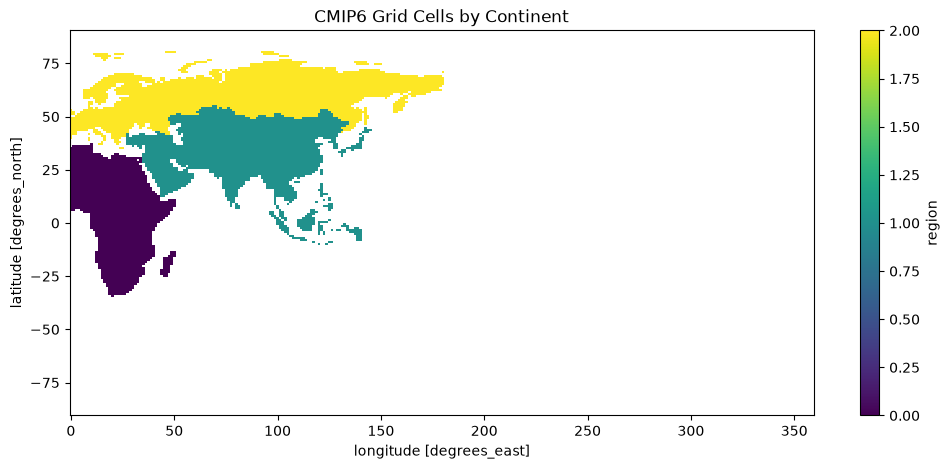

In [10]:
# Step 8: Create continent masks

import geopandas as gpd
import regionmask
import matplotlib.pyplot as plt

# Load Natural Earth country boundaries
url = (
    "https://raw.githubusercontent.com/nvkelso/"
    "natural-earth-vector/master/geojson/"
    "ne_110m_admin_0_countries.geojson"
)

world = gpd.read_file(url)

# Select five continents
selected_continents = [
    "North America",
    "South America",
    "Europe",
    "Africa",
    "Asia"
]

world = world[
    world["CONTINENT"].isin(selected_continents)
]

# Combine countries into continents
continent_shapes = (
    world.dissolve(by="CONTINENT")
    .reset_index()
)

# Create regionmask definitions
continents = regionmask.from_geopandas(
    continent_shapes,
    names="CONTINENT",
    overlap=False
)

# Create mask for CMIP6 grid
continent_mask = continents.mask(
    ds_h.lon,
    ds_h.lat,
    wrap_lon=360
)

print("Available continents:")
for number, name in zip(
    continents.numbers,
    continents.names
):
    print(number, name)

print("\nMask dimensions:", continent_mask.shape)

# Visualize geographic regions
continent_mask.plot(figsize=(12, 5))
plt.title("CMIP6 Grid Cells by Continent")
plt.show()


Continent coverage:
Africa: 1833 grid cells
Asia: 2619 grid cells
Europe: 3067 grid cells
North America: 0 grid cells
South America: 0 grid cells


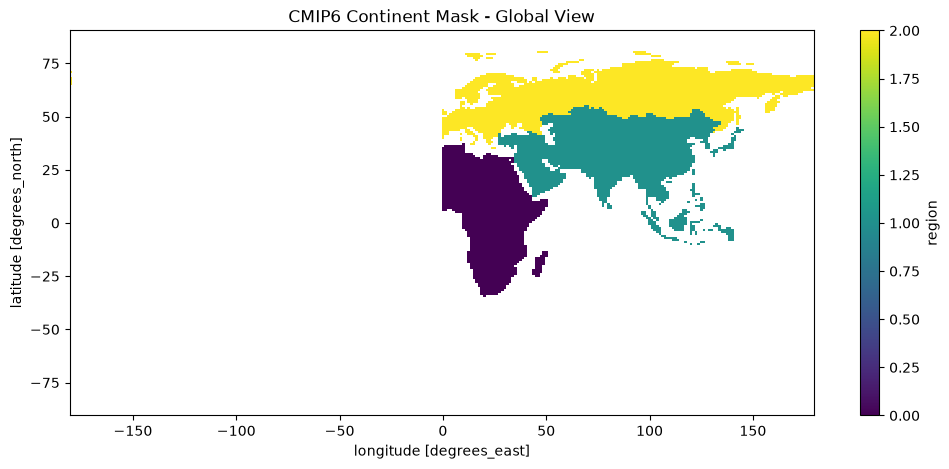

In [11]:
# Step 8.1: Check continent coverage

import numpy as np
import matplotlib.pyplot as plt

print("Continent coverage:")
for number, name in zip(continents.numbers, continents.names):
    count = int(np.sum(continent_mask.values == number))
    print(f"{name}: {count} grid cells")

# Display with longitude from -180 to 180
mask_display = continent_mask.assign_coords(
    lon=((continent_mask.lon + 180) % 360) - 180
).sortby("lon")

plt.figure(figsize=(12, 5))
mask_display.plot()
plt.title("CMIP6 Continent Mask - Global View")
plt.show()


Continent coverage after correction:
Africa: 2170 grid cells
Asia: 2619 grid cells
Europe: 3188 grid cells
North America: 3190 grid cells
South America: 1318 grid cells


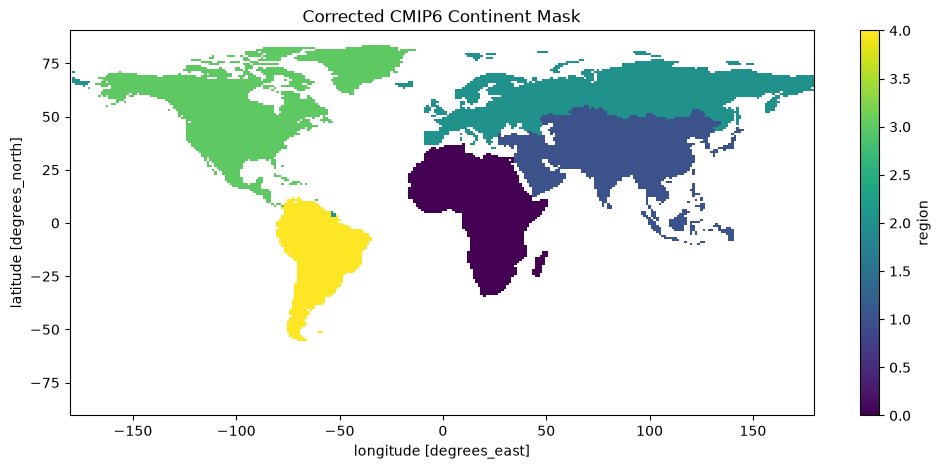

In [12]:
# Step 8.2: Fix continent mask longitude

import numpy as np
import matplotlib.pyplot as plt

# Convert CMIP6 longitude from 0-360 to -180 to 180
lon_fixed = ((ds_h.lon + 180) % 360) - 180

# Recreate mask using corrected longitude
continent_mask = continents.mask(
    lon_fixed,
    ds_h.lat,
    wrap_lon=False
)

print("Continent coverage after correction:")

for number, name in zip(continents.numbers, continents.names):
    count = int(np.sum(continent_mask.values == number))
    print(f"{name}: {count} grid cells")

# Display global map
mask_display = continent_mask.assign_coords(
    lon=lon_fixed
).sortby("lon")

plt.figure(figsize=(12, 5))
mask_display.plot()
plt.title("Corrected CMIP6 Continent Mask")
plt.show()


In [13]:
# Step 9: Calculate annual temperatures by continent

import numpy as np
import pandas as pd
import xarray as xr
import os

# Use latitude-based area weights
lat_weights = np.cos(np.deg2rad(ds_h.lat))

# Select years
historical = ds_h["tas"].sel(time=slice("1950", "2014"))
future = ds_f["tas"].sel(time=slice("2015", "2100"))

results = []

# Process each continent
for number, name in zip(continents.numbers, continents.names):

    print("Processing:", name)

    # Select continent grid cells
    region_weights = lat_weights.where(continent_mask == number, 0)

    # Weighted mean temperature for each month
    hist_mean = historical.weighted(region_weights).mean(
        dim=("lat", "lon")
    )

    future_mean = future.weighted(region_weights).mean(
        dim=("lat", "lon")
    )

    # Convert monthly values to annual means
    hist_annual = hist_mean.groupby("time.year").mean()
    future_annual = future_mean.groupby("time.year").mean()

    # Baseline: 1995-2014
    baseline = hist_annual.sel(year=slice(1995, 2014)).mean()

    # Calculate temperature anomalies
    hist_anomaly = hist_annual - baseline
    future_anomaly = future_annual - baseline

    # Load results
    hist_values = hist_anomaly.compute().values
    future_values = future_anomaly.compute().values

    # Save historical data
    for year, value in zip(hist_annual.year.values, hist_values):
        results.append({
            "year": int(year),
            "region": name,
            "scenario": "historical",
            "temperature_anomaly": float(value)
        })

    # Save future data
    for year, value in zip(future_annual.year.values, future_values):
        results.append({
            "year": int(year),
            "region": name,
            "scenario": "ssp585",
            "temperature_anomaly": float(value)
        })

# Convert to DataFrame
regional_df = pd.DataFrame(results)

# Save to CSV
os.makedirs("data", exist_ok=True)

regional_df.to_csv(
    "data/regional_temperatures.csv",
    index=False
)

print("\nFinished!")
print(regional_df.head())
print("\nTotal rows:", len(regional_df))


Processing: Africa
Processing: Asia
Processing: Europe
Processing: North America
Processing: South America

Finished!
   year  region    scenario  temperature_anomaly
0  1950  Africa  historical            -0.681028
1  1951  Africa  historical            -0.464144
2  1952  Africa  historical            -0.564561
3  1953  Africa  historical            -0.857269
4  1954  Africa  historical            -0.825089

Total rows: 755


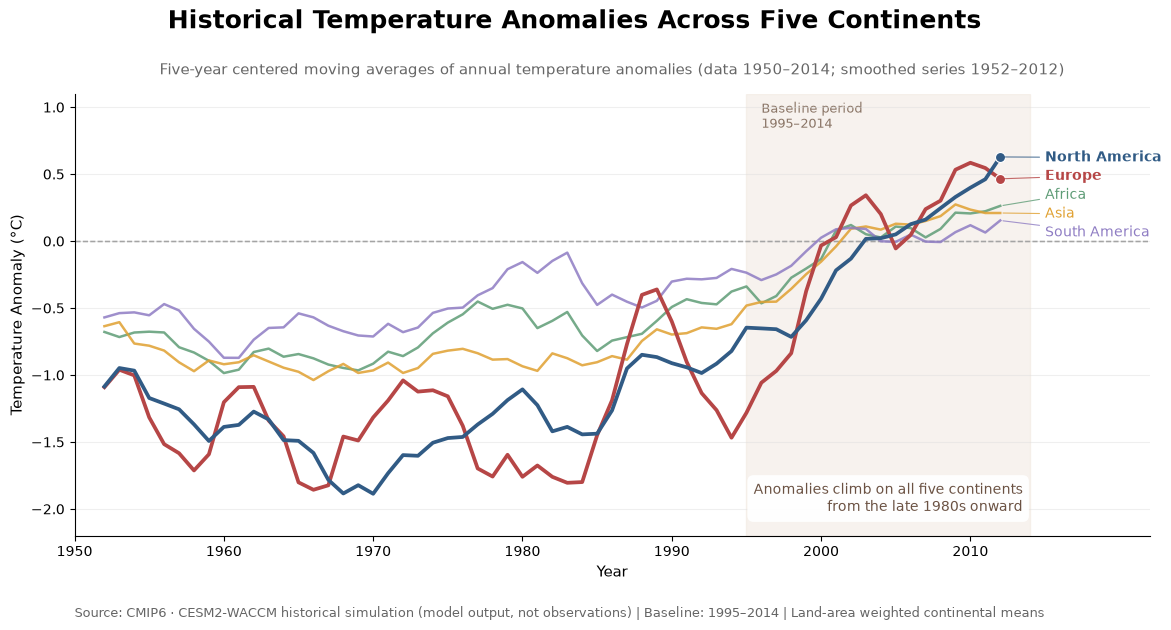

Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph1_historical_trends_annotated.png


In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

hist = regional_df[regional_df["scenario"] == "historical"].copy()
hist = hist.sort_values(["region", "year"])

hist["smoothed"] = (
    hist.groupby("region")["temperature_anomaly"]
    .transform(lambda s: s.rolling(window=5, center=True, min_periods=5).mean())
)

colors = {
    "Africa": "#5E9C76",
    "Asia": "#E0A030",
    "Europe": "#B64646",
    "North America": "#315B85",
    "South America": "#8E7CC3",
}
highlight_regions = ["Europe", "North America"]

fig, ax = plt.subplots(figsize=(12.5, 6.5), facecolor="white")

ax.axvspan(1995, 2014, color="#F1E9E0", alpha=0.55, zorder=0)
ax.text(
    1996, 1.05, "Baseline period\n1995–2014",
    fontsize=9, color="#8A7566", ha="left", va="top", zorder=1
)

end_points = {}
for region in colors:
    group = hist[(hist["region"] == region) & (hist["smoothed"].notna())].sort_values("year")
    is_hl = region in highlight_regions

    ax.plot(
        group["year"], group["smoothed"],
        color=colors[region],
        linewidth=2.7 if is_hl else 1.8,
        alpha=1.0 if is_hl else 0.85,
        zorder=3 if is_hl else 2,
    )
    last = group.iloc[-1]
    end_points[region] = (last["year"], last["smoothed"])

ax.axhline(y=0, color="#777777", linestyle="--", linewidth=1, zorder=1)

min_gap = 0.14
order = sorted(end_points, key=lambda r: end_points[r][1])
ys = [end_points[r][1] for r in order]

adj = ys.copy()
for i in range(1, len(adj)):
    adj[i] = max(adj[i], adj[i - 1] + min_gap)
adj = [y + (np.mean(ys) - np.mean(adj)) for y in adj]

for region, y_lab in zip(order, adj):
    x_end, y_end = end_points[region]
    is_hl = region in highlight_regions
    if is_hl:
        ax.scatter(x_end, y_end, color=colors[region], s=52,
                   edgecolor="white", linewidth=0.8, zorder=7)
    ax.annotate(
        region,
        xy=(x_end, y_end),
        xytext=(x_end + 3, y_lab),
        color=colors[region], fontsize=10,
        fontweight="bold" if is_hl else "normal",
        va="center", ha="left",
        arrowprops=dict(arrowstyle="-", color=colors[region], lw=0.8, alpha=0.8),
        zorder=7,
    )

ax.text(
    2013.5, -2.05,
    "Anomalies climb on all five continents\nfrom the late 1980s onward",
    fontsize=10, color="#6B5243",
    ha="right", va="bottom",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="none", alpha=0.95),
    zorder=6,
)

fig.suptitle(
    "Historical Temperature Anomalies Across Five Continents",
    fontsize=18, fontweight="bold", y=0.97
)
ax.set_title(
    "Five-year centered moving averages of annual temperature anomalies "
    "(data 1950–2014; smoothed series 1952–2012)",
    fontsize=11, color="#666666", pad=14
)

ax.set_xlabel("Year", fontsize=11)
ax.set_ylabel("Temperature Anomaly (°C)", fontsize=11)

ax.set_xlim(1950, 2022)
ax.set_xticks(range(1950, 2020, 10))
ax.set_ylim(-2.2, 1.1)

ax.grid(axis="y", color="#DDDDDD", alpha=0.45, linewidth=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="both", labelsize=10)

fig.text(
    0.10, 0.035,
    "Source: CMIP6 · CESM2-WACCM historical simulation (model output, not observations) | "
    "Baseline: 1995–2014 | Land-area weighted continental means",
    fontsize=9, color="#666666"
)

fig.subplots_adjust(left=0.10, right=0.96, bottom=0.16, top=0.84)

if Path("proposal/proposal.md").exists():
    output_dir = Path("proposal/figures")
else:
    output_dir = Path("../proposal/figures")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "graph1_historical_trends_annotated.png"
plt.savefig(output_path, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()

print("Saved to:", output_path.resolve())

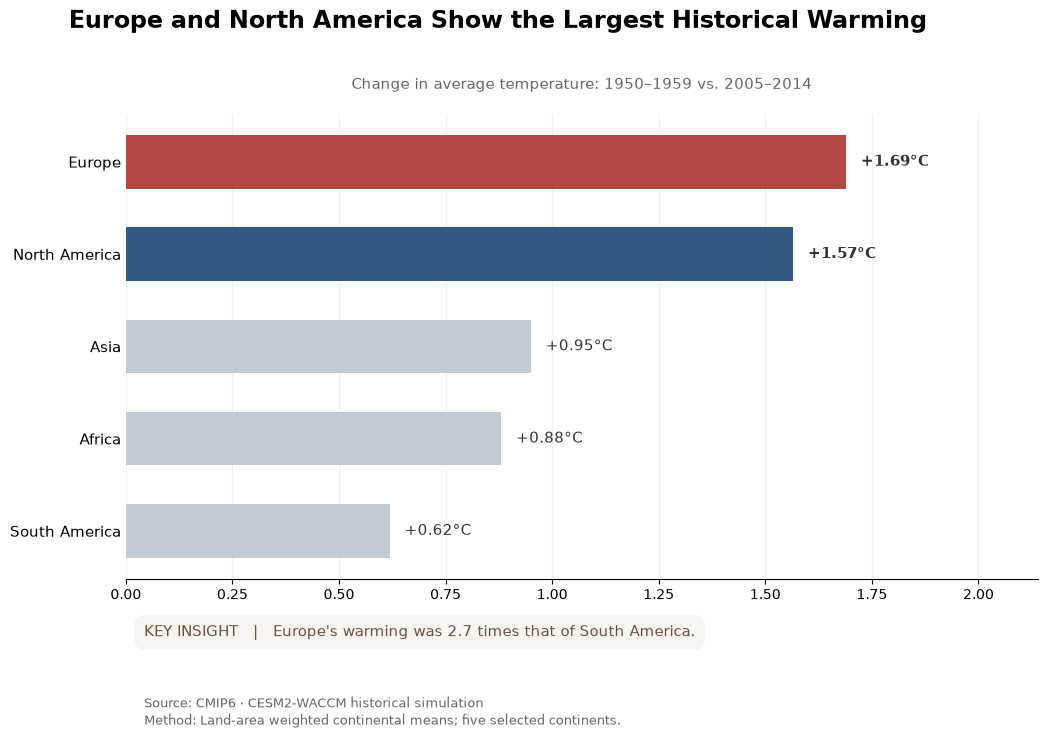

Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph2_warming_ranking_annotated.png

Historical warming by continent:
region
Europe           1.689
North America    1.565
Asia             0.950
Africa           0.881
South America    0.619
Name: temperature_anomaly, dtype: float64


In [34]:
# Step 11: Final Annotated Historical Warming Ranking

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path


hist = regional_df[
    regional_df["scenario"] == "historical"
].copy()

early = (
    hist[hist["year"].between(1950, 1959)]
    .groupby("region")["temperature_anomaly"]
    .mean()
)

late = (
    hist[hist["year"].between(2005, 2014)]
    .groupby("region")["temperature_anomaly"]
    .mean()
)

warming = (late - early).sort_values(ascending=False)


colors = {
    "Europe": "#B64646",
    "North America": "#315B85",
    "Asia": "#C4CBD0",
    "Africa": "#C4CBD0",
    "South America": "#C4CBD0"
}

bar_colors = [
    colors.get(region, "#C4CBD0")
    for region in warming.index
]


fig = plt.figure(figsize=(12, 8), facecolor="white")

gs = GridSpec(
    3, 1,
    figure=fig,
    height_ratios=[7.5, 1.1, 0.6],
    hspace=0.12
)

ax = fig.add_subplot(gs[0])
insight_ax = fig.add_subplot(gs[1])
source_ax = fig.add_subplot(gs[2])

# Keep annotation sections separate
insight_ax.axis("off")
source_ax.axis("off")


y = np.arange(len(warming))

bars = ax.barh(
    y,
    warming.values,
    color=bar_colors,
    height=0.58,
    zorder=3
)

ax.set_yticks(y)
ax.set_yticklabels(warming.index, fontsize=11)

ax.invert_yaxis()


for i, value in enumerate(warming.values):

    ax.text(
        value + 0.035,
        i,
        f"+{value:.2f}°C",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold" if i < 2 else "normal",
        color="#333333"
    )


fig.suptitle(
    "Europe and North America Show the Largest "
    "Historical Warming",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

ax.set_title(
    "Change in average temperature: "
    "1950–1959 vs. 2005–2014",
    fontsize=11,
    color="#666666",
    pad=18
)

ax.set_xlabel(
    "Temperature Increase (°C)",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

ax.set_xlim(0, warming.max() + 0.45)

ax.grid(
    axis="x",
    alpha=0.18,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)


ratio = warming["Europe"] / warming["South America"]

insight_ax.text(
    0.02, 0.55,
    f"KEY INSIGHT   |   Europe's warming was "
    f"{ratio:.1f} times that of South America.",
    fontsize=11,
    color="#6B5243",
    va="center",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#F7F3EF",
        edgecolor="none"
    ),
    transform=insight_ax.transAxes
)


source_ax.text(
    0.02, 0.50,
    "Source: CMIP6 · CESM2-WACCM historical simulation\n"
    "Method: Land-area weighted continental means; "
    "five selected continents.",
    fontsize=9,
    color="#666666",
    ha="left",
    va="center",
    linespacing=1.5,
    transform=source_ax.transAxes
)


fig.subplots_adjust(
    left=0.19,
    right=0.95,
    top=0.84,
    bottom=0.07
)


if Path("proposal/proposal.md").exists():
    output_dir = Path("proposal/figures")
else:
    output_dir = Path("../proposal/figures")

output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "graph2_warming_ranking_annotated.png"
)

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", output_path.resolve())
print("\nHistorical warming by continent:")
print(warming.round(3))




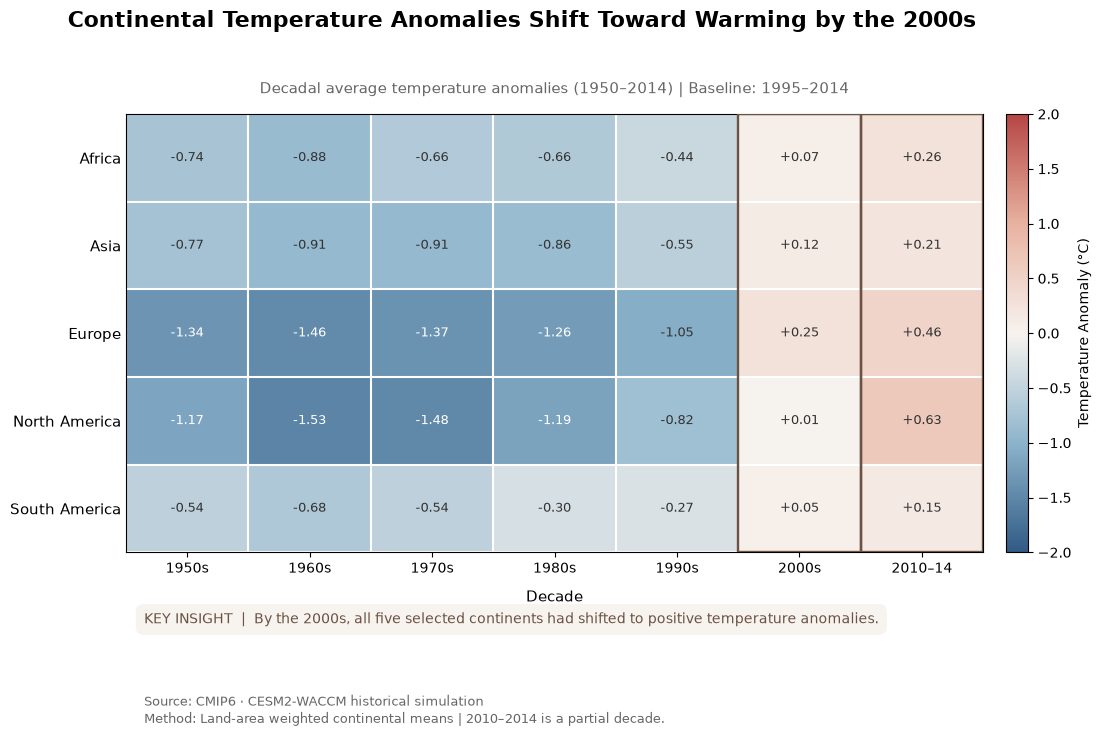

Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph3_decade_heatmap_annotated.png

Decadal temperature anomalies:
decade         1950  1960  1970  1980  1990  2000  2010
region                                                 
Africa        -0.74 -0.88 -0.66 -0.66 -0.44  0.07  0.26
Asia          -0.77 -0.91 -0.91 -0.86 -0.55  0.12  0.21
Europe        -1.34 -1.46 -1.37 -1.26 -1.05  0.25  0.46
North America -1.17 -1.53 -1.48 -1.19 -0.82  0.01  0.63
South America -0.54 -0.68 -0.54 -0.30 -0.27  0.05  0.15


In [41]:
# Step 12: Final Annotated Decadal Temperature Heatmap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from matplotlib.patches import Rectangle
from pathlib import Path

hist = regional_df[
    regional_df["scenario"] == "historical"
].copy()

hist["decade"] = (hist["year"] // 10) * 10

decade_data = hist.pivot_table(
    index="region",
    columns="decade",
    values="temperature_anomaly",
    aggfunc="mean"
)

region_order = [
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America"
]

decade_data = decade_data.reindex(region_order)

cmap = LinearSegmentedColormap.from_list(
    "academic_diverging",
    [
        "#315B85",
        "#8DB4CC",
        "#F7F3EF",
        "#E8B2A0",
        "#B64646"
    ]
)

norm = TwoSlopeNorm(
    vmin=-2,
    vcenter=0,
    vmax=2
)

fig = plt.figure(
    figsize=(12, 8),
    facecolor="white"
)

gs = GridSpec(
    3, 1,
    figure=fig,
    height_ratios=[7.5, 1.1, 0.7],
    hspace=0.20
)

ax = fig.add_subplot(gs[0])
insight_ax = fig.add_subplot(gs[1])
source_ax = fig.add_subplot(gs[2])

insight_ax.axis("off")
source_ax.axis("off")

im = ax.imshow(
    decade_data.values,
    cmap=cmap,
    norm=norm,
    aspect="auto"
)

decade_cols = list(decade_data.columns)

ax.set_xticks(
    np.arange(len(decade_cols))
)

ax.set_xticklabels(
    [
        "2010–14" if d == 2010 else f"{d}s"
        for d in decade_cols
    ],
    fontsize=10
)

ax.set_yticks(
    np.arange(len(decade_data.index))
)

ax.set_yticklabels(
    decade_data.index,
    fontsize=11
)

ax.set_xlabel(
    "Decade",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel("")

for i in range(decade_data.shape[0]):
    for j in range(decade_data.shape[1]):

        value = decade_data.iloc[i, j]

        if pd.isna(value):
            continue

        text_color = (
            "white" if abs(value) >= 1.15
            else "#333333"
        )

        ax.text(
            j,
            i,
            f"{value:+.2f}",
            ha="center",
            va="center",
            fontsize=9,
            color=text_color,
            fontweight="medium"
        )

# Highlight the decades when all continents
# show positive temperature anomalies
for decade in [2000, 2010]:

    if decade in decade_cols:

        col_idx = decade_cols.index(decade)

        rect = Rectangle(
            (col_idx - 0.5, -0.5),
            1,
            len(region_order),
            fill=False,
            edgecolor="#6B5243",
            linewidth=1.7,
            zorder=5
        )

        ax.add_patch(rect)

ax.set_xticks(
    np.arange(-0.5, len(decade_cols), 1),
    minor=True
)

ax.set_yticks(
    np.arange(-0.5, len(region_order), 1),
    minor=True
)

ax.grid(
    which="minor",
    color="white",
    linewidth=1.5
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

ax.tick_params(
    axis="y",
    length=0
)

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_label(
    "Temperature Anomaly (°C)",
    fontsize=10
)

fig.suptitle(
    "Continental Temperature Anomalies Shift "
    "Toward Warming by the 2000s",
    fontsize=16,
    fontweight="bold",
    y=0.97
)

ax.set_title(
    "Decadal average temperature anomalies "
    "(1950–2014) | Baseline: 1995–2014",
    fontsize=11,
    color="#666666",
    pad=15
)

insight_ax.text(
    0.02,
    0.52,
    "KEY INSIGHT  |  By the 2000s, all five selected "
    "continents had shifted to positive temperature anomalies.",
    fontsize=10,
    color="#6B5243",
    va="center",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#F7F3EF",
        edgecolor="none"
    ),
    transform=insight_ax.transAxes
)

source_ax.text(
    0.02,
    0.50,
    "Source: CMIP6 · CESM2-WACCM historical simulation\n"
    "Method: Land-area weighted continental means | "
    "2010–2014 is a partial decade.",
    fontsize=9,
    color="#666666",
    ha="left",
    va="center",
    linespacing=1.5,
    transform=source_ax.transAxes
)

fig.subplots_adjust(
    left=0.17,
    right=0.93,
    top=0.84,
    bottom=0.07
)

if Path("proposal/proposal.md").exists():
    output_dir = Path("proposal/figures")
else:
    output_dir = Path("../proposal/figures")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    output_dir /
    "graph3_decade_heatmap_annotated.png"
)

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", output_path.resolve())

print("\nDecadal temperature anomalies:")
print(decade_data.round(2))




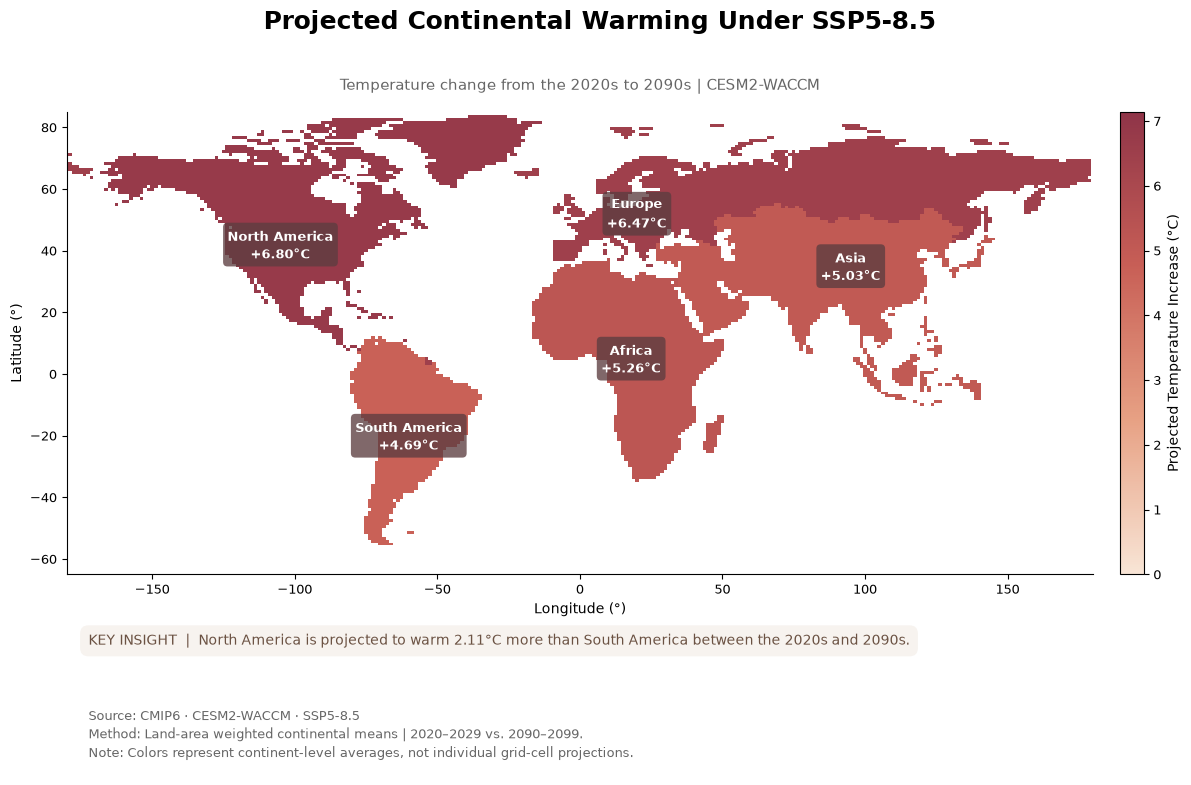

Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph4_future_warming_map_annotated.png

Projected warming by continent:
region
North America    6.80
South America    4.69
Europe           6.47
Africa           5.26
Asia             5.03
Name: temperature_anomaly, dtype: float64

Largest regional warming gap: 2.11 °C


In [42]:
# Step 13: Annotated Future Warming Map

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize, LinearSegmentedColormap
from pathlib import Path

future_df = regional_df[
    regional_df["scenario"] == "ssp585"
].copy()

early = (
    future_df[future_df["year"].between(2020, 2029)]
    .groupby("region")["temperature_anomaly"]
    .mean()
)

late = (
    future_df[future_df["year"].between(2090, 2099)]
    .groupby("region")["temperature_anomaly"]
    .mean()
)

warming = late - early

region_order = [
    "North America",
    "South America",
    "Europe",
    "Africa",
    "Asia"
]

warming = warming.reindex(region_order)

if warming.isna().any():
    missing = warming[warming.isna()].index.tolist()
    raise ValueError(f"Missing projection data for: {missing}")

highest_region = warming.idxmax()
lowest_region = warming.idxmin()
warming_gap = warming.max() - warming.min()

warming_map = np.full(
    continent_mask.shape,
    np.nan,
    dtype=float
)

for number, name in zip(
    continents.numbers,
    continents.names
):
    if name in warming.index:
        warming_map[
            continent_mask.values == number
        ] = warming[name]

lon_values = (
    (continent_mask.lon.values + 180) % 360
) - 180

order = np.argsort(lon_values)

warming_map = warming_map[:, order]

lon_sorted = lon_values[order]
lat_values = continent_mask.lat.values

cmap = LinearSegmentedColormap.from_list(
    "warming_palette",
    [
        "#F8E5D6",
        "#E7A184",
        "#C85F56",
        "#8F3448"
    ]
)

cmap.set_bad("white")

norm = Normalize(
    vmin=0,
    vmax=max(0.5, float(warming.max()) * 1.05)
)

fig = plt.figure(
    figsize=(13, 8.5),
    facecolor="white"
)

gs = GridSpec(
    3, 1,
    figure=fig,
    height_ratios=[7.5, 1.0, 1.1],
    hspace=0.18
)

ax = fig.add_subplot(gs[0])
insight_ax = fig.add_subplot(gs[1])
source_ax = fig.add_subplot(gs[2])

insight_ax.axis("off")
source_ax.axis("off")

im = ax.pcolormesh(
    lon_sorted,
    lat_values,
    warming_map,
    cmap=cmap,
    norm=norm,
    shading="auto",
    rasterized=True
)

ax.set_xlim(-180, 180)
ax.set_ylim(-65, 85)

ax.set_xlabel(
    "Longitude (°)",
    fontsize=10
)

ax.set_ylabel(
    "Latitude (°)",
    fontsize=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(labelsize=9)

# Label continents with projected warming
label_positions = {
    "North America": (-105, 42),
    "South America": (-60, -20),
    "Europe": (20, 52),
    "Africa": (18, 5),
    "Asia": (95, 35)
}

for region, (lon, lat) in label_positions.items():

    ax.text(
        lon,
        lat,
        f"{region}\n+{warming[region]:.2f}°C",
        fontsize=9,
        fontweight="bold",
        ha="center",
        va="center",
        color="#FFFFFF",
        linespacing=1.4,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="#5C3D40",
            edgecolor="none",
            alpha=0.78
        ),
        zorder=5
    )

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.025
)

cbar.set_label(
    "Projected Temperature Increase (°C)",
    fontsize=10
)

cbar.ax.tick_params(labelsize=9)

fig.suptitle(
    "Projected Continental Warming Under SSP5-8.5",
    fontsize=18,
    fontweight="bold",
    y=0.97
)

ax.set_title(
    "Temperature change from the 2020s to 2090s | "
    "CESM2-WACCM",
    fontsize=11,
    color="#666666",
    pad=16
)

insight_ax.text(
    0.02,
    0.50,
    f"KEY INSIGHT  |  {highest_region} is projected to warm "
    f"{warming_gap:.2f}°C more than {lowest_region} "
    f"between the 2020s and 2090s.",
    fontsize=10,
    color="#6B5243",
    va="center",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#F7F3EF",
        edgecolor="none"
    ),
    transform=insight_ax.transAxes
)

source_ax.text(
    0.02,
    0.60,
    "Source: CMIP6 · CESM2-WACCM · SSP5-8.5\n"
    "Method: Land-area weighted continental means | "
    "2020–2029 vs. 2090–2099.\n"
    "Note: Colors represent continent-level averages, "
    "not individual grid-cell projections.",
    fontsize=9,
    color="#666666",
    ha="left",
    va="center",
    linespacing=1.5,
    transform=source_ax.transAxes
)

fig.subplots_adjust(
    left=0.09,
    right=0.93,
    top=0.85,
    bottom=0.07
)

if Path("proposal/proposal.md").exists():
    output_dir = Path("proposal/figures")
else:
    output_dir = Path("../proposal/figures")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    output_dir /
    "graph4_future_warming_map_annotated.png"
)

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", output_path.resolve())

print("\nProjected warming by continent:")
print(warming.round(2))

print(
    "\nLargest regional warming gap:",
    round(warming_gap, 2),
    "°C"
)



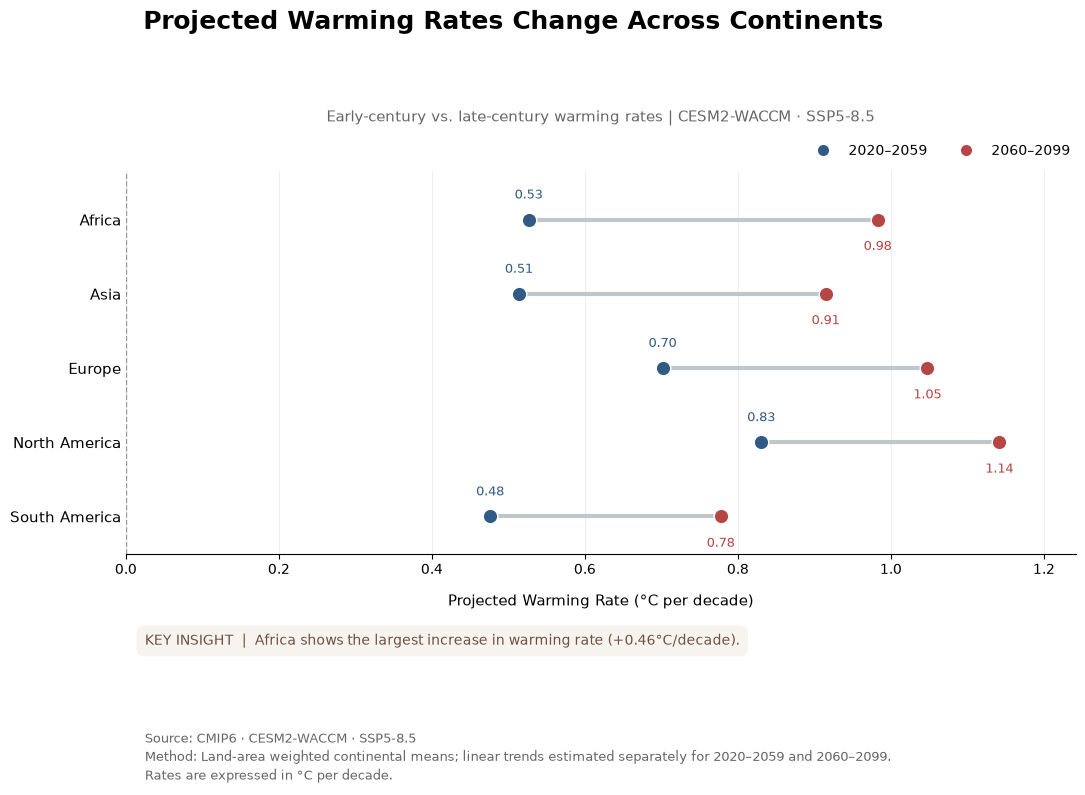

Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph5_warming_rate_changes_annotated.png

Projected warming rates (°C per decade):
period         2020–2059  2060–2099  change
region                                     
Africa             0.526      0.983   0.456
Asia               0.514      0.915   0.401
Europe             0.701      1.048   0.346
North America      0.830      1.142   0.311
South America      0.476      0.778   0.301


In [45]:

# Step 14: Annotated Projected Warming Rate Changes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from pathlib import Path

future = regional_df[
    (regional_df["scenario"] == "ssp585") &
    (regional_df["year"].between(2020, 2099))
].copy()

region_order = [
    "Africa",
    "Asia",
    "Europe",
    "North America",
    "South America"
]

rates = []

for region in region_order:

    group = future[
        future["region"] == region
    ].sort_values("year")

    for period, start, end in [
        ("2020–2059", 2020, 2059),
        ("2060–2099", 2060, 2099)
    ]:

        period_data = group[
            group["year"].between(start, end)
        ].dropna(subset=["temperature_anomaly"])

        if period_data["year"].nunique() < 2:
            raise ValueError(
                f"Insufficient data for {region}, {period}"
            )

        slope = np.polyfit(
            period_data["year"].to_numpy(),
            period_data["temperature_anomaly"].to_numpy(),
            1
        )[0]

        rates.append({
            "region": region,
            "period": period,
            "warming_rate": slope * 10
        })

rates_df = pd.DataFrame(rates)

rate_table = rates_df.pivot(
    index="region",
    columns="period",
    values="warming_rate"
).reindex(region_order)

rate_table["change"] = (
    rate_table["2060–2099"] -
    rate_table["2020–2059"]
)

rate_table = rate_table.sort_values(
    "change",
    ascending=False
)

largest_increase_region = rate_table["change"].idxmax()
largest_increase = rate_table["change"].max()

early_color = "#315B85"
late_color = "#B64646"
line_color = "#BFC7CC"

fig = plt.figure(
    figsize=(12.5, 8.5),
    facecolor="white"
)

gs = GridSpec(
    3, 1,
    figure=fig,
    height_ratios=[7.2, 1.0, 1.0],
    hspace=0.38
)

ax = fig.add_subplot(gs[0])
insight_ax = fig.add_subplot(gs[1])
source_ax = fig.add_subplot(gs[2])

insight_ax.axis("off")
source_ax.axis("off")

y = np.arange(len(rate_table))

for i, (region, row) in enumerate(
    rate_table.iterrows()
):

    early_rate = row["2020–2059"]
    late_rate = row["2060–2099"]

    ax.plot(
        [early_rate, late_rate],
        [i, i],
        color=line_color,
        linewidth=3,
        solid_capstyle="round",
        zorder=2
    )

    ax.scatter(
        early_rate,
        i,
        color=early_color,
        s=110,
        edgecolor="white",
        linewidth=1,
        zorder=4
    )

    ax.scatter(
        late_rate,
        i,
        color=late_color,
        s=110,
        edgecolor="white",
        linewidth=1,
        zorder=4
    )

    ax.annotate(
        f"{early_rate:.2f}",
        xy=(early_rate, i),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
        color=early_color
    )

    ax.annotate(
        f"{late_rate:.2f}",
        xy=(late_rate, i),
        xytext=(0, -15),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9,
        color=late_color
    )

ax.set_yticks(y)

ax.set_yticklabels(
    rate_table.index,
    fontsize=11
)

ax.invert_yaxis()

# Extra vertical padding keeps labels inside the plot
ax.set_ylim(
    len(rate_table) - 0.5,
    -0.65
)

ax.set_xlabel(
    "Projected Warming Rate (°C per decade)",
    fontsize=11,
    labelpad=12
)

ax.axvline(
    0,
    color="#999999",
    linestyle="--",
    linewidth=1,
    zorder=1
)

all_rates = rate_table[
    ["2020–2059", "2060–2099"]
].to_numpy()

xmin = float(np.nanmin(all_rates))
xmax = float(np.nanmax(all_rates))
padding = max((xmax - xmin) * 0.15, 0.10)

ax.set_xlim(
    min(0, xmin - padding),
    xmax + padding
)

ax.grid(
    axis="x",
    color="#DDDDDD",
    alpha=0.45,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(
    axis="y",
    length=0
)

legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=early_color,
        markeredgecolor="white",
        markersize=9,
        label="2020–2059"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=late_color,
        markeredgecolor="white",
        markersize=9,
        label="2060–2099"
    )
]

# Move legend above the plotting area
ax.legend(
    handles=legend_handles,
    frameon=False,
    loc="lower right",
    bbox_to_anchor=(1.0, 1.02),
    ncol=2,
    fontsize=10,
    columnspacing=1.8,
    borderaxespad=0
)

fig.suptitle(
    "Projected Warming Rates Change Across Continents",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

ax.set_title(
    "Early-century vs. late-century warming rates | "
    "CESM2-WACCM · SSP5-8.5",
    fontsize=11,
    color="#666666",
    pad=36
)

if largest_increase > 0:

    insight = (
        f"KEY INSIGHT  |  {largest_increase_region} shows "
        f"the largest increase in warming rate "
        f"(+{largest_increase:.2f}°C/decade)."
    )

else:

    insight = (
        "KEY INSIGHT  |  All five continents show "
        "stable or declining warming rates "
        "between the two periods."
    )

insight_ax.text(
    0.02,
    0.52,
    insight,
    fontsize=10,
    color="#6B5243",
    va="center",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#F7F3EF",
        edgecolor="none"
    ),
    transform=insight_ax.transAxes
)

source_ax.text(
    0.02,
    0.50,
    "Source: CMIP6 · CESM2-WACCM · SSP5-8.5\n"
    "Method: Land-area weighted continental means; "
    "linear trends estimated separately for "
    "2020–2059 and 2060–2099.\n"
    "Rates are expressed in °C per decade.",
    fontsize=9,
    color="#666666",
    va="center",
    ha="left",
    linespacing=1.5,
    transform=source_ax.transAxes
)

fig.subplots_adjust(
    left=0.19,
    right=0.95,
    top=0.79,
    bottom=0.07
)

if Path("proposal/proposal.md").exists():
    output_dir = Path("proposal/figures")
else:
    output_dir = Path("../proposal/figures")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    output_dir /
    "graph5_warming_rate_changes_annotated.png"
)

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", output_path.resolve())

print("\nProjected warming rates (°C per decade):")
print(rate_table.round(3))


Using future dataset: ds_f


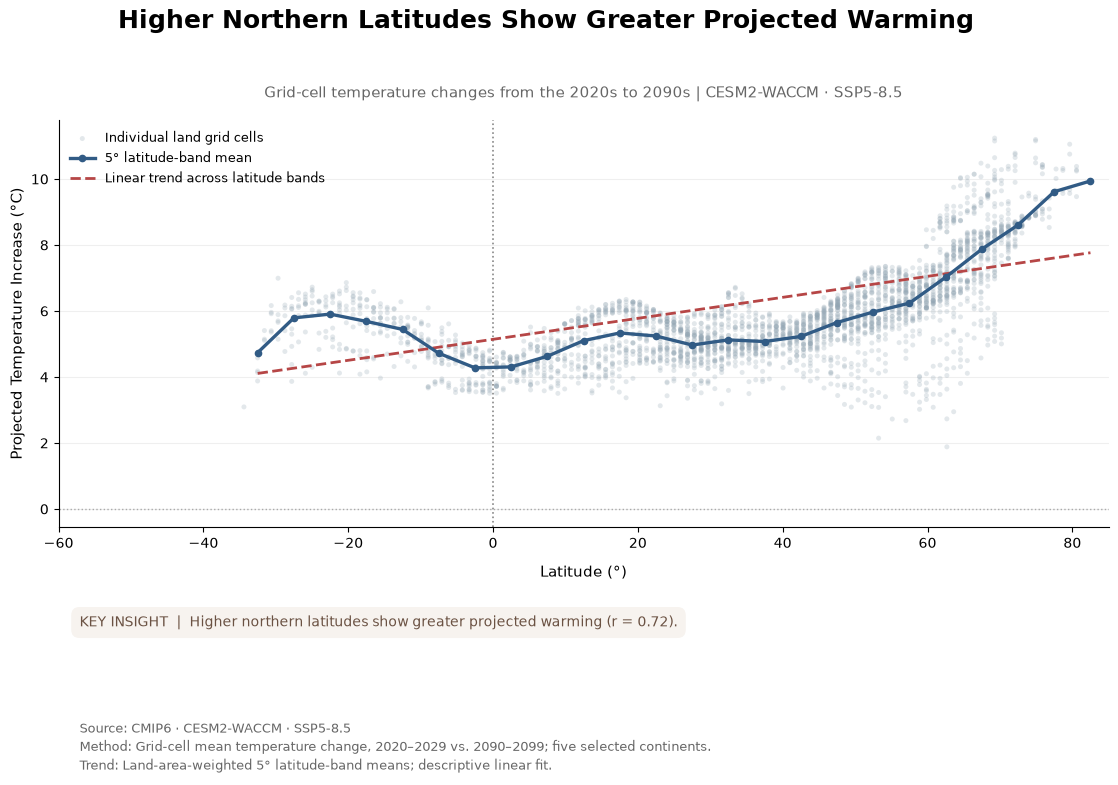

Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph6_latitude_warming_annotated.png

Number of land grid cells: 7519
Number of latitude bands: 24
Latitude-band correlation: 0.717
Trend slope (°C per degree latitude): 0.0318


In [48]:
# Step 15: Annotated Latitude vs. Projected Temperature Change

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path

# Find the future CMIP6 dataset
future_candidates = [
    "ds_f",
    "ds_future",
    "ds_ssp585",
    "ds_s",
    "ds_ssp",
    "future_ds"
]

ds_future = None

for name in future_candidates:
    candidate = globals().get(name)

    if (
        isinstance(candidate, xr.Dataset)
        and "tas" in candidate
        and "time" in candidate.coords
        and "lat" in candidate.coords
        and "lon" in candidate.coords
    ):
        ds_future = candidate
        print("Using future dataset:", name)
        break

if ds_future is None:
    raise ValueError(
        "Future CMIP6 dataset not found. "
        "Set ds_future to your SSP5-8.5 xarray dataset."
    )

tas_future = ds_future["tas"]

# Select the two future periods
early = tas_future.where(
    (tas_future.time.dt.year >= 2020) &
    (tas_future.time.dt.year <= 2029),
    drop=True
)

late = tas_future.where(
    (tas_future.time.dt.year >= 2090) &
    (tas_future.time.dt.year <= 2099),
    drop=True
)

if early.sizes["time"] == 0 or late.sizes["time"] == 0:
    raise ValueError(
        "The future dataset must contain both "
        "2020–2029 and 2090–2099."
    )

# Compare period means at each grid cell
warming_grid = (
    late.mean(dim="time") -
    early.mean(dim="time")
)

# Temperature differences in K equal differences in °C
warming_grid = warming_grid.squeeze(drop=True)

if set(warming_grid.dims) != {"lat", "lon"}:
    raise ValueError(
        "Expected a 2D lat/lon grid. "
        f"Found dimensions: {warming_grid.dims}"
    )

# Create a land mask using the five selected continents
land_mask = continents.mask(
    warming_grid.lon,
    warming_grid.lat,
    wrap_lon=360
)

warming_grid = warming_grid.where(
    land_mask.notnull()
)

# Convert the grid to a table for plotting
grid_df = (
    warming_grid
    .to_dataframe(name="warming")
    .reset_index()
)

grid_df = grid_df[
    ["lat", "lon", "warming"]
].dropna()

grid_df = grid_df[
    grid_df["warming"].between(-10, 20)
].copy()

if grid_df.empty:
    raise ValueError("No valid land-grid warming values found.")

# Sample grid cells for readability, without changing
# the full data used for latitude-band averages
scatter_df = grid_df.sample(
    n=min(3000, len(grid_df)),
    random_state=42
).copy()

# Aggregate temperatures into 5-degree latitude bands
grid_df["lat_band"] = (
    np.floor(grid_df["lat"] / 5) * 5 + 2.5
)

grid_df["area_weight"] = np.cos(
    np.deg2rad(grid_df["lat"])
).clip(lower=0)

band_stats = (
    grid_df.groupby("lat_band")
    .apply(
        lambda g: pd.Series({
            "warming": np.average(
                g["warming"],
                weights=g["area_weight"]
            ),
            "n_cells": len(g)
        }),
        include_groups=False
    )
    .reset_index()
    .sort_values("lat_band")
)

band_stats = band_stats[
    band_stats["n_cells"] >= 3
].copy()

if len(band_stats) < 2:
    raise ValueError(
        "Not enough latitude bands for trend analysis."
    )

# Fit a descriptive linear trend to latitude-band means
slope, intercept = np.polyfit(
    band_stats["lat_band"],
    band_stats["warming"],
    1
)

trend_x = np.linspace(
    band_stats["lat_band"].min(),
    band_stats["lat_band"].max(),
    200
)

trend_y = slope * trend_x + intercept

correlation = band_stats[
    "lat_band"
].corr(band_stats["warming"])

fig = plt.figure(
    figsize=(12.5, 8.5),
    facecolor="white"
)

gs = GridSpec(
    3, 1,
    figure=fig,
    height_ratios=[7.5, 1.0, 1.0],
    hspace=0.40
)

ax = fig.add_subplot(gs[0])
insight_ax = fig.add_subplot(gs[1])
source_ax = fig.add_subplot(gs[2])

insight_ax.axis("off")
source_ax.axis("off")

# Raw grid-cell observations
ax.scatter(
    scatter_df["lat"],
    scatter_df["warming"],
    s=13,
    color="#92A5B3",
    alpha=0.25,
    edgecolors="none",
    label="Individual land grid cells",
    zorder=2
)

# Latitude-band mean warming
ax.plot(
    band_stats["lat_band"],
    band_stats["warming"],
    color="#315B85",
    linewidth=2.4,
    marker="o",
    markersize=4.5,
    label="5° latitude-band mean",
    zorder=4
)

# Overall latitude trend
ax.plot(
    trend_x,
    trend_y,
    color="#B64646",
    linewidth=2,
    linestyle="--",
    label="Linear trend across latitude bands",
    zorder=3
)

ax.axvline(
    0,
    color="#888888",
    linestyle=":",
    linewidth=1.2,
    zorder=1
)

ax.axhline(
    0,
    color="#AAAAAA",
    linestyle=":",
    linewidth=1,
    zorder=1
)

ax.set_xlim(-60, 85)

ax.set_xlabel(
    "Latitude (°)",
    fontsize=11,
    labelpad=10
)

ax.set_ylabel(
    "Projected Temperature Increase (°C)",
    fontsize=11
)

ax.grid(
    axis="y",
    color="#DDDDDD",
    alpha=0.45,
    linewidth=0.8
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    frameon=False,
    loc="upper left",
    fontsize=9,
    ncol=1
)

fig.suptitle(
    "Higher Northern Latitudes Show Greater Projected Warming",
    fontsize=18,
    fontweight="bold",
    y=0.97
)

ax.set_title(
    "Grid-cell temperature changes from the 2020s "
    "to 2090s | CESM2-WACCM · SSP5-8.5",
    fontsize=11,
    color="#666666",
    pad=16
)

if correlation > 0:
    insight = (
        "KEY INSIGHT  |  Higher northern latitudes show "
        "greater projected warming "
        f"(r = {correlation:.2f})."
    )
elif correlation < 0:
    insight = (
        "KEY INSIGHT  |  Latitude-band averages show "
        "a negative latitude–warming association "
        f"(r = {correlation:.2f})."
    )
else:
    insight = (
        "KEY INSIGHT  |  No linear association "
        "between latitude and projected warming."
    )

insight_ax.text(
    0.02,
    0.52,
    insight,
    fontsize=10,
    color="#6B5243",
    va="center",
    ha="left",
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#F7F3EF",
        edgecolor="none"
    ),
    transform=insight_ax.transAxes
)

source_ax.text(
    0.02,
    0.50,
    "Source: CMIP6 · CESM2-WACCM · SSP5-8.5\n"
    "Method: Grid-cell mean temperature change, "
    "2020–2029 vs. 2090–2099; five selected continents.\n"
    "Trend: Land-area-weighted 5° latitude-band means; "
    "descriptive linear fit.",
    fontsize=9,
    color="#666666",
    ha="left",
    va="center",
    linespacing=1.5,
    transform=source_ax.transAxes
)

fig.subplots_adjust(
    left=0.11,
    right=0.95,
    top=0.84,
    bottom=0.07
)

if Path("proposal/proposal.md").exists():
    output_dir = Path("proposal/figures")
else:
    output_dir = Path("../proposal/figures")

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    output_dir /
    "graph6_latitude_warming_annotated.png"
)

fig.savefig(
    output_path,
    dpi=400
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", output_path.resolve())

print("\nNumber of land grid cells:", len(grid_df))
print("Number of latitude bands:", len(band_stats))
print("Latitude-band correlation:", round(correlation, 3))
print("Trend slope (°C per degree latitude):", round(slope, 4))


In [54]:
from pathlib import Path

figures_dir = Path(
    "/Users/jing/Documents/GitHub/dsc106-final-project/notebooks/proposal/figures"
)

for file in sorted(figures_dir.glob("*.png")):
    print(file.name)

graph1_historical_trends.png
graph2_warming_ranking.png
graph3_decade_heatmap.png
graph4_future_comparison.png
graph4_future_projections.png
graph4_future_warming_map.png
graph4_future_warming_ranking.png
graph5_latitude_warming.png


In [55]:

# Find all final annotated graphs

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

print("Project root:", project_root.resolve())

for number in range(1, 7):

    matches = sorted(
        project_root.rglob(
            f"graph{number}*annotated*.png"
        )
    )

    print(f"\nGraph {number}:")

    if matches:
        for path in matches:
            print("FOUND:", path.resolve())
    else:
        print("NOT FOUND")


Project root: /Users/jing/Documents/GitHub/dsc106-final-project

Graph 1:
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph1_historical_trends_annotated.png

Graph 2:
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph2_warming_ranking_annotated.png

Graph 3:
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph3_decade_heatmap_annotated.png

Graph 4:
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph4_future_warming_map_annotated.png

Graph 5:
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph5_future_projections_annotated.png
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph5_warming_rate_changes_annotated.png

Graph 6:
FOUND: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/figures/graph6_latitude_warming_annotated.png


In [79]:
# Step 16: Export High-Resolution Final Project Proposal PDF

from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import Rectangle
from PIL import Image
import matplotlib.pyplot as plt
import textwrap
import os

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

proposal_dir = project_root / "proposal"
figures_dir = proposal_dir / "figures"

proposal_dir.mkdir(parents=True, exist_ok=True)

figure_files = [
    "graph1_historical_trends_annotated.png",
    "graph2_warming_ranking_annotated.png",
    "graph3_decade_heatmap_annotated.png",
    "graph4_future_warming_map_annotated.png",
    "graph5_warming_rate_changes_annotated.png",
    "graph6_latitude_warming_annotated.png"
]

graph_titles = [
    "Historical Temperature Trends",
    "Historical Warming Ranking",
    "Decadal Temperature Heatmap",
    "Future Continental Warming Map",
    "Projected Warming Rate Changes",
    "Latitude vs. Projected Warming"
]

for filename in figure_files:
    image_path = figures_dir / filename

    if not image_path.is_file():
        raise FileNotFoundError(
            f"Missing figure: {image_path}"
        )

    with Image.open(image_path) as check_img:
        check_img.verify()

team_members = [
    ("Jingyun Xiong", "j8xiong@ucsd.edu"),
    ("Jacey Chow", "j6chow@ucsd.edu"),
    ("Maggie Shao", "yis082@ucsd.edu"),
    ("Weder Qin", "w7qin@ucsd.edu")
]

project_title = (
    "Climate Change: Global Temperature Trends "
    "and Future Predictions"
)

dataset = (
    "CMIP6 (Coupled Model Intercomparison Project "
    "Phase 6) - CESM2-WACCM"
)

research_question = (
    "How have temperature trends varied across world "
    "regions, and which regions are projected to "
    "experience the greatest warming in the future?"
)


brief_writeup = (
    "Our project investigates regional variations in historical "
    "and projected temperature changes using CMIP6 data from "
    "the CESM2-WACCM climate model. "
    "We analyze historical simulations (1950–2014) and future "
    "projections (2020–2099) under the SSP5-8.5 emissions scenario, "
    "focusing on geographic differences rather than comparisons "
    "across scenarios. "
    "Our analysis examines five continents: North America, "
    "South America, Europe, Africa, and Asia. "
    "Using line charts, bar charts, heatmaps, geographic maps, "
    "dumbbell charts, and scatter plots, we compare historical "
    "warming patterns, projected temperature increases, "
    "and changes in warming rates. "
    "We also investigate the relationship between latitude "
    "and projected warming, particularly at higher northern latitudes. "
    "Our final interactive website will allow users to select "
    "regions and explore temperature changes over time. "
    "Our goal is to communicate regional climate differences "
    "through spatial and temporal analysis. "
    "As our analysis uses a single climate model and emissions "
    "scenario for future projections, the results are model-specific "
    "rather than certain future outcomes."
)


navy = "#315B85"
brown = "#90776D"
dark = "#30343B"
gray = "#626B73"
light = "#F7F3EF"

pdf_path = (
    proposal_dir /
    "DSC106_Final_Project_Proposal.pdf"
)

temp_pdf_path = (
    proposal_dir /
    "DSC106_Final_Project_Proposal_building.pdf"
)

def add_section(ax, title, y):
    ax.text(
        0.06,
        y,
        title,
        fontsize=12,
        fontweight="bold",
        color=navy,
        ha="left",
        va="top",
        transform=ax.transAxes
    )

    return y - 0.030


def add_paragraph(ax, content, y, width=100):

    lines = textwrap.wrap(
        content,
        width=width,
        break_long_words=False
    )

    for line in lines:
        ax.text(
            0.06,
            y,
            line,
            fontsize=9.2,
            color=dark,
            ha="left",
            va="top",
            transform=ax.transAxes
        )

        y -= 0.019

    return y - 0.012


page_count = 0

with PdfPages(temp_pdf_path) as pdf:

    fig = plt.figure(
        figsize=(11, 8.5),
        facecolor="white"
    )

    ax = fig.add_axes([
        0.12, 0.055, 0.76, 0.90
    ])

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    ax.text(
        0.5,
        0.985,
        "DSC 106",
        fontsize=12,
        fontweight="bold",
        color=brown,
        ha="center",
        va="top",
        transform=ax.transAxes
    )

    ax.text(
        0.5,
        0.942,
        "FINAL PROJECT PROPOSAL",
        fontsize=21,
        fontweight="bold",
        color=navy,
        ha="center",
        va="top",
        transform=ax.transAxes
    )

    ax.plot(
        [0.06, 0.94],
        [0.895, 0.895],
        color=brown,
        linewidth=1.5,
        transform=ax.transAxes
    )

    y = 0.865

    y = add_section(
        ax, "PROJECT TITLE", y
    )

    y = add_paragraph(
        ax, project_title, y
    )

    y = add_section(
        ax, "TEAM MEMBERS", y
    )

    y -= 0.018

    for i, (name, email) in enumerate(team_members):

        if i % 2 == 0:
            ax.add_patch(
                Rectangle(
                    (0.045, y - 0.015),
                    0.91,
                    0.030,
                    facecolor=light,
                    edgecolor="none",
                    transform=ax.transAxes,
                    zorder=0
                )
            )

        ax.text(
            0.06,
            y,
            name,
            fontsize=10,
            color=dark,
            va="center",
            transform=ax.transAxes
        )

        ax.text(
            0.48,
            y,
            email,
            fontsize=10,
            color=dark,
            va="center",
            transform=ax.transAxes
        )

        y -= 0.030

    y -= 0.018

    y = add_section(
        ax, "DATASET", y
    )

    y = add_paragraph(
        ax, dataset, y
    )

    y = add_section(
        ax, "RESEARCH QUESTION", y
    )

    y = add_paragraph(
        ax, research_question, y
    )

    y = add_section(
        ax, "BRIEF WRITEUP", y
    )

    y = add_paragraph(
        ax,
        brief_writeup,
        y,
        width=100
    )

    y = add_section(
        ax, "PLANNED VISUALIZATIONS", y
    )

    for i, title in enumerate(graph_titles, 1):
        ax.text(
            0.06,
            y,
            f"{i:02d}   {title}",
            fontsize=9.5,
            color=dark,
            va="top",
            transform=ax.transAxes
        )

        y -= 0.020

    if y < 0.025:
        plt.close(fig)
        raise ValueError(
            "Page 1 content exceeds available space. "
            "Reduce spacing in add_paragraph."
        )

    pdf.savefig(
        fig,
        dpi=300,
        facecolor="white"
    )

    plt.close(fig)
    page_count += 1

    for i in range(0, len(figure_files), 2):

        fig = plt.figure(
            figsize=(11, 8.5),
            facecolor="white"
        )

        positions = [
            [0.025, 0.505, 0.95, 0.47],
            [0.025, 0.025, 0.95, 0.47]
        ]

        for j in range(2):

            index = i + j

            if index >= len(figure_files):
                break

            image_path = (
                figures_dir /
                figure_files[index]
            )

            with Image.open(image_path) as source:
                img = source.convert("RGB").copy()

            ax_img = fig.add_axes(positions[j])

            ax_img.imshow(
                img,
                interpolation="nearest",
                aspect="equal",
                resample=False
            )

            ax_img.set_anchor("C")
            ax_img.axis("off")

            print(
                f"Graph {index + 1}: "
                f"{img.width} x {img.height} pixels"
            )

        pdf.savefig(
            fig,
            dpi=400,
            facecolor="white"
        )

        plt.close(fig)
        page_count += 1

if page_count != 4:
    raise ValueError(
        f"Expected 4 pages, generated {page_count}."
    )

if temp_pdf_path.stat().st_size < 1000:
    raise ValueError(
        "Generated PDF is unexpectedly small."
    )

with open(temp_pdf_path, "rb") as f:
    header = f.read(8)
    f.seek(max(0, temp_pdf_path.stat().st_size - 1024))
    trailer = f.read()

if not header.startswith(b"%PDF-") or b"%%EOF" not in trailer:
    raise ValueError(
        "Generated PDF failed basic file checks."
    )

os.replace(temp_pdf_path, pdf_path)

print("\nProposal PDF successfully generated!")
print("Saved to:", pdf_path.resolve())
print("Total pages:", page_count)
print(
    "File size:",
    round(pdf_path.stat().st_size / (1024 * 1024), 2),
    "MB"
)
print("Graph page export resolution: 400 DPI")



Graph 1: 4639 x 2523 pixels
Graph 2: 3147 x 2220 pixels
Graph 3: 3307 x 2220 pixels
Graph 4: 3570 x 2355 pixels
Graph 5: 3261 x 2385 pixels
Graph 6: 3355 x 2357 pixels

Proposal PDF successfully generated!
Saved to: /Users/jing/Documents/GitHub/dsc106-final-project/proposal/DSC106_Final_Project_Proposal.pdf
Total pages: 4
File size: 1.24 MB
Graph page export resolution: 400 DPI


## Cell 3 — metadata check: units, calendar, time coverage, grid (1-D vs 2-D coordinates), California-box cell count

In [ ]:
CA = dict(lat_min=32.5, lat_max=42.0, lon_min=-124.5, lon_max=-114.0)  # bounding box around California

def coord_names(ds):
    latn = next(n for n in ["lat", "latitude", "nav_lat"] if n in ds.variables)
    lonn = next(n for n in ["lon", "longitude", "nav_lon"] if n in ds.variables)
    return latn, lonn

def inspect(row):
    out = dict(source_id=row.source_id, experiment_id=row.experiment_id)
    try:
        ds = xr.open_zarr(gcs.get_mapper(row.zstore), consolidated=True)
        latn, lonn = coord_names(ds)
        lat, lon = ds[latn].values, ds[lonn].values
        out["coord_dims"] = f"{lat.ndim}D"            # check BEFORE counting cells
        if lat.ndim == 1:
            LAT, LON = np.meshgrid(lat, lon, indexing="ij")
            dlat, dlon = np.abs(np.diff(lat)).mean(), np.abs(np.diff(lon)).mean()
        else:
            LAT, LON = lat, lon
            dlat, dlon = np.abs(np.diff(lat, axis=0)).mean(), np.abs(np.diff(lon, axis=1)).mean()
        L = LON % 360
        inbox = ((LAT >= CA["lat_min"]) & (LAT <= CA["lat_max"]) &
                 (L >= CA["lon_min"] % 360) & (L <= CA["lon_max"] % 360))
        out.update(units=ds["tas"].attrs.get("units"),
                   tas_dims=",".join(ds["tas"].dims),
                   calendar=ds.time.encoding.get("calendar", "?"),
                   span=f"{str(ds.time.values[0])[:7]}→{str(ds.time.values[-1])[:7]}",
                   ntime=ds.sizes["time"],
                   nlat=LAT.shape[0], nlon=LAT.shape[1],
                   dlat=round(float(dlat), 2), dlon=round(float(dlon), 2),
                   lon_range=f"{np.nanmin(lon):.1f}..{np.nanmax(lon):.1f}", ca_cells=int(inbox.sum()))
    except Exception as e:
        out["error"] = repr(e)[:100]
    return out

with ThreadPoolExecutor(8) as ex:
    res = pd.DataFrame(list(ex.map(inspect, cands.itertuples())))
if "error" not in res: res["error"] = np.nan

spans = res.pivot(index="source_id", columns="experiment_id", values="span").add_suffix("_span")
units_all = res.groupby("source_id").units.agg(lambda s: ",".join(sorted(set(map(str, s)))))
grid = (res[res.experiment_id == "ssp585"]
          .set_index("source_id")[["coord_dims", "tas_dims", "calendar", "nlat", "nlon", "dlat", "dlon", "lon_range", "ca_cells"]])
summary = (short.set_index("source_id")
             .join(grid).join(spans).join(units_all.rename("units"))
             .sort_values("dlat"))
errs = res.dropna(subset=["error"])
if len(errs): print("ERRORS:\n", errs[["source_id", "experiment_id", "error"]].to_string())
print(summary.to_string())
summary.to_csv("stage1_model_check.csv")

## Cell 4 — choose model and scope from the Cell 3 table

Rules (applied in code, then checked by eye):
1. Complete coverage: historical 1850-01 → 2014-12, both SSPs 2015-01 → ≥ 2100-12; units `K` in all three runs; no errors.
2. California scope only if: 1-D lat/lon coordinates, grid spacing ≤ 1.3° in both directions, ≥ 40 cells in the box, and a land-fraction file (`sftlf`) exists so ocean cells can be excluded. Otherwise fall back to a global area-weighted mean.
3. Among eligible models prefer member `r1i1p1f1`, native grid `gn`, then spacing closest to 1° (enough California cells while keeping the download manageable).

In [ ]:
MODEL_OVERRIDE = None     # set to a source_id string to force a choice

s = summary.reset_index().fillna({"historical_span": "", "ssp126_span": "", "ssp585_span": ""})
first = lambda c: s[c].str[:7]; last = lambda c: s[c].str[-7:]
s["complete"] = (first("historical_span").le("1850-12") & last("historical_span").ge("2014-12") &
                 first("ssp126_span").eq("2015-01") & last("ssp126_span").ge("2100-12") &
                 first("ssp585_span").eq("2015-01") & last("ssp585_span").ge("2100-12") &
                 s.units.eq("K") & ~s.source_id.isin(errs.source_id))
s["ca_ok"] = (s.complete & s.has_sftlf & s.coord_dims.eq("1D") &
              s.dlat.le(1.3) & s.dlon.le(1.3) & s.ca_cells.ge(40))
s["rank"] = list(zip(s.member_id != "r1i1p1f1", s.grid_label != "gn", (s.dlat - 1.0).abs(), s.source_id))
print("complete models:", int(s.complete.sum()), "| California-eligible:", int(s.ca_ok.sum()))
print(s[s.ca_ok].sort_values("rank")[["source_id","member_id","grid_label","dlat","dlon","ca_cells","calendar"]].head(10).to_string(index=False))

pool = s[s.ca_ok] if s.ca_ok.any() else s[s.complete & s.coord_dims.eq("1D")]
choice = (s[s.source_id == MODEL_OVERRIDE] if MODEL_OVERRIDE else pool.sort_values("rank")).iloc[0]
MODEL, MEMBER, GRID = choice.source_id, choice.member_id, choice.grid_label
SCOPE = "california_box" if bool(choice.ca_ok) else "global"
print(f"\nCHOSEN: {MODEL} {MEMBER} {GRID} | scope={SCOPE} | dlat={choice.dlat} dlon={choice.dlon} | box cells={choice.ca_cells} | calendar={choice.calendar}")
STORES = cands[(cands.source_id == MODEL)].set_index("experiment_id").zstore.to_dict()
for k, v in STORES.items(): print(k, v)

## Cell 5 — extract regional and global series

* Spatial mean: area-weighted with cos(latitude). California: cells whose centres fall in the box **and** whose land fraction ≥ 50 %.
* Global area-weighted mean is computed in the same pass (same chunks) for context.
* Monthly → calendar-year mean weighted by days in month (model calendar). K → °C.
* Baseline: same model's historical 1995–2014 mean (IPCC AR6 reference period).

In [ ]:
def open_tas(exp):
    return xr.open_zarr(gcs.get_mapper(STORES[exp]), consolidated=True)["tas"]

ds_h = open_tas("historical").sel(time=slice("1950-01", "2014-12"))
ds_1 = open_tas("ssp126").sel(time=slice("2015-01", "2100-12"))
ds_5 = open_tas("ssp585").sel(time=slice("2015-01", "2100-12"))
for n, d in [("hist", ds_h), ("ssp126", ds_1), ("ssp585", ds_5)]:
    print(n, d.dims, d.shape, d.attrs.get("units"))
assert np.allclose(ds_1.lat, ds_5.lat) and np.allclose(ds_1.lon, ds_5.lon) and np.allclose(ds_h.lat, ds_5.lat)

lat, lon = ds_5.lat, ds_5.lon
coslat = np.cos(np.deg2rad(lat))
w_glob = coslat * xr.ones_like(lon)

if SCOPE == "california_box":
    lf_row = lf_cat[(lf_cat.source_id == MODEL) & (lf_cat.grid_label == GRID)].sort_values("version").iloc[-1]
    sftlf = xr.open_zarr(gcs.get_mapper(lf_row.zstore), consolidated=True)["sftlf"].squeeze(drop=True).load()
    frac = sftlf.values / (100.0 if float(sftlf.max()) > 1.5 else 1.0)
    land = xr.DataArray(frac >= 0.5, dims=("lat", "lon"), coords={"lat": lat, "lon": lon})
    lon360 = lon % 360
    box = ((lat >= CA["lat_min"]) & (lat <= CA["lat_max"]) &
           (lon360 >= CA["lon_min"] % 360) & (lon360 <= CA["lon_max"] % 360))
    w_reg = (coslat * box * land).astype(float)
    cells = w_reg.where(w_reg > 0, drop=True)
    print("sftlf store:", lf_row.zstore)
    print("land cells used:", int((w_reg > 0).sum()), "of", int(box.sum()), "box cells")
    print("cell-centre lats:", np.round(cells.lat.values, 2)); print("cell-centre lons:", np.round(((cells.lon + 180) % 360) - 180, 2).values)
else:
    w_reg = w_glob

def spatial(da):
    return xr.Dataset({"reg": da.weighted(w_reg).mean(("lat", "lon")),
                       "glob": da.weighted(w_glob).mean(("lat", "lon"))})

def annual(ds):
    w = ds.time.dt.days_in_month
    out = (ds * w).groupby("time.year").sum() / w.groupby("time.year").sum()
    out["n_months"] = ds.reg.groupby("time.year").count()
    return out

import time; t0 = time.time()
ann = {k: annual(spatial(d)).compute() for k, d in [("hist", ds_h), ("ssp126", ds_1), ("ssp585", ds_5)]}
print(f"computed in {time.time()-t0:.0f}s")

## Cell 6 — verify and export `data/tas_scenarios_annual.csv` (2015–2100) and `data/tas_historical_annual.csv` (1950–2014)

In [ ]:
import os, json
K = 273.15
a1, a5, ah = ann["ssp126"], ann["ssp585"], ann["hist"]
base_reg = float(ah.reg.sel(year=slice(1995, 2014)).mean()) - K
base_glob = float(ah.glob.sel(year=slice(1995, 2014)).mean()) - K

df = pd.DataFrame({
    "year": a1.year.values.astype(int),
    "ssp126_c": a1.reg.values - K,
    "ssp585_c": a5.reg.sel(year=a1.year).values - K,
})
df["gap_c"] = df.ssp585_c - df.ssp126_c
df["ssp126_anom_c"] = df.ssp126_c - base_reg
df["ssp585_anom_c"] = df.ssp585_c - base_reg
df["global_ssp126_c"] = a1.glob.values - K
df["global_ssp585_c"] = a5.glob.sel(year=a1.year).values - K
df["global_gap_c"] = df.global_ssp585_c - df.global_ssp126_c
df = df.round(3)

hist = pd.DataFrame({"year": ah.year.values.astype(int), "hist_c": ah.reg.values - K,
                     "hist_anom_c": ah.reg.values - K - base_reg, "global_hist_c": ah.glob.values - K}).round(3)

# ---- verification ----
yrs = list(range(2015, 2101))
assert df.year.tolist() == yrs, "years not exactly 2015..2100"
assert df.year.is_unique and not df.isna().any().any(), "duplicates or NaN"
assert (a1.n_months.values == 12).all() and (a5.sel(year=a1.year).n_months.values == 12).all(), "incomplete years"
assert hist.year.tolist() == list(range(1950, 2015)) and not hist.isna().any().any()
print("VERIFIED: 86 rows, years 2015-2100, 12 months each, no missing/duplicate years, no NaN")

os.makedirs("data", exist_ok=True)
df.to_csv("data/tas_scenarios_annual.csv", index=False)
hist.to_csv("data/tas_historical_annual.csv", index=False)
meta = dict(model=MODEL, member=MEMBER, grid=GRID, scope=SCOPE, region_box=CA,
            land_threshold="sftlf >= 50%" if SCOPE == "california_box" else None,
            variable="tas (near-surface air temperature), monthly Amon, converted K -> degC",
            annual="calendar-year mean weighted by days in month",
            spatial="cos(latitude) area weights", baseline="historical 1995-2014 mean",
            baseline_reg_c=round(base_reg, 3), baseline_glob_c=round(base_glob, 3),
            stores=STORES)
json.dump(meta, open("data/metadata.json", "w"), indent=2)
print(json.dumps(meta, indent=2))
print("----- tas_scenarios_annual.csv -----"); print(df.to_csv(index=False))
print("----- tas_historical_annual.csv -----"); print(hist.to_csv(index=False))

## Results of the checkpoint run (Colab, 2026-11-02)

* Catalog: 523,774 stores; `tas`/`Amon` stores: 635 historical, 329 SSP1-2.6, 327 SSP5-8.5.
* 311 (model, member, grid) triples have all three experiments, spanning 44 models; **37 models** pass the coverage/units checks; all candidate grids use **1-D** lat/lon coordinates.
* 14 models qualify for a California average (≤ 1.3° grid, ≥ 40 box cells, land-fraction file).
* **Chosen:** `CESM2-WACCM` · `r1i1p1f1` · `gn` (0.94° × 1.25°, `noleap` calendar, units K in all three runs).
  * historical `gs://cmip6/CMIP6/CMIP/NCAR/CESM2-WACCM/historical/r1i1p1f1/Amon/tas/gn/v20190227/`
  * ssp126 `gs://cmip6/CMIP6/ScenarioMIP/NCAR/CESM2-WACCM/ssp126/r1i1p1f1/Amon/tas/gn/v20210211/`
  * ssp585 `gs://cmip6/CMIP6/ScenarioMIP/NCAR/CESM2-WACCM/ssp585/r1i1p1f1/Amon/tas/gn/v20200702/`
  * land fraction (fixed field, same grid) `gs://cmip6/CMIP6/ScenarioMIP/NCAR/CESM2-WACCM/ssp534-over/r5i1p1f1/fx/sftlf/gn/v20200305/`
* **Region:** California bounding box 32.5–42°N, 124.5–114°W, land cells with land fraction ≥ 50 % → 64 of 88 cells (box also includes most of Nevada and small parts of OR/AZ/Baja). Area weights cos(lat).
* **Verification:** both scenarios have exactly one value per year 2015–2100 (86 rows), 12 months each, no NaN/duplicates. Historical 1950–2014 also complete.
* **Baseline** (1995–2014, historical run): California box 14.744 °C; global 14.740 °C.
* Exports: `data/tas_scenarios_annual.csv`, `data/tas_historical_annual.csv`, `data/metadata.json`.
